In [93]:
!pip install timm -q


In [94]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

import timm

In [95]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


## Data Preparation

Dataset: **Brain Tumor MRI** (`final_dataset_clean`) -- classes: glioma, meningioma, notumor, pituitary.

Total 6892 image-ke stratified (class-wise) **80:10:10** train/val/test e vag kora hoyeche, `SEED = 42` diye. Split ta 4 ta notebook-e hubohu ek (train 5513, val 689, test 690)।

In [96]:
for root, dirs, files in os.walk("/kaggle/input/datasets/shuvosingh/brain-tumor-mri-dataset/Brain_Tumor_MRI_Dataset_Final"):
    if 'train' in dirs:
        print(root)

/kaggle/input/datasets/shuvosingh/brain-tumor-mri-dataset/Brain_Tumor_MRI_Dataset_Final


In [97]:
import os
import shutil
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms

DATA_DIR = "/kaggle/input/datasets/shuvosingh/brain-tumor-mri-dataset/Brain_Tumor_MRI_Dataset_Final"
CLEAN_DIR = "/kaggle/working/prepared_dataset_clean"
SEED = 42
IMG_EXTS = (".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff")

paths, labels = [], []
for root, dirs, files in os.walk(DATA_DIR):
    dirs.sort()
    for f in sorted(files):
        if f.lower().endswith(IMG_EXTS):
            paths.append(os.path.join(root, f))
            labels.append(os.path.basename(root))

paths = np.array(paths)
labels = np.array(labels)
classes = sorted(set(labels))
class_count = len(classes)
print("Classes found:", classes)
print("Total images:", len(paths))

tr_p, tmp_p, tr_l, tmp_l = train_test_split(paths, labels, test_size=0.20, stratify=labels, random_state=SEED)
va_p, te_p, va_l, te_l = train_test_split(tmp_p, tmp_l, test_size=0.50, stratify=tmp_l, random_state=SEED)

if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

rows = {"train": [], "val": [], "test": []}
for split, ps, ls in (("train", tr_p, tr_l), ("val", va_p, va_l), ("test", te_p, te_l)):
    for i, (p, c) in enumerate(zip(ps, ls)):
        dst_dir = os.path.join(CLEAN_DIR, split, str(c))
        os.makedirs(dst_dir, exist_ok=True)
        dst = os.path.join(dst_dir, f"{i}_{os.path.basename(p)}")
        shutil.copy2(p, dst)
        rows[split].append((dst, str(c)))

n = len(paths)
for split in ("train", "val", "test"):
    cnt = Counter(c for _, c in rows[split])
    print(f"{split}: {len(rows[split])} ({len(rows[split]) / n * 100:.1f}%)", dict(sorted(cnt.items())))

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = datasets.ImageFolder(os.path.join(CLEAN_DIR, "train"), transform=train_transform)
val_dataset = datasets.ImageFolder(os.path.join(CLEAN_DIR, "val"), transform=eval_transform)
test_dataset = datasets.ImageFolder(os.path.join(CLEAN_DIR, "test"), transform=eval_transform)

class_names = train_dataset.classes
assert train_dataset.classes == val_dataset.classes == test_dataset.classes

print("\nFinal class_names:", class_names)
print("Train:", len(train_dataset), " Val:", len(val_dataset), " Test:", len(test_dataset))

Classes found: [np.str_('glioma'), np.str_('meningioma'), np.str_('no_tumor'), np.str_('pituitary')]
Total images: 5941
train: 4752 (80.0%) {'glioma': 1753, 'meningioma': 1182, 'no_tumor': 629, 'pituitary': 1188}
val: 594 (10.0%) {'glioma': 219, 'meningioma': 148, 'no_tumor': 79, 'pituitary': 148}
test: 595 (10.0%) {'glioma': 219, 'meningioma': 148, 'no_tumor': 79, 'pituitary': 149}

Final class_names: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Train: 4752  Val: 594  Test: 595


In [98]:
from collections import Counter

for name, ds in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]:
    counts = Counter([label for _, label in ds.samples])
    print(name, {class_names[k]: v for k, v in sorted(counts.items())})


train {'glioma': 1753, 'meningioma': 1182, 'no_tumor': 629, 'pituitary': 1188}
val {'glioma': 219, 'meningioma': 148, 'no_tumor': 79, 'pituitary': 148}
test {'glioma': 219, 'meningioma': 148, 'no_tumor': 79, 'pituitary': 149}


In [99]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)


In [100]:
from torchvision import models
import torch.nn as nn

cnn_model = models.densenet169(weights="IMAGENET1K_V1")

cnn_features = cnn_model.classifier.in_features
cnn_model.classifier = nn.Identity()

In [101]:
# ===== CELL 8 - ViT Backbone =====
vit_model = timm.create_model(
    'vit_tiny_patch16_224',
    pretrained=True
)

vit_features = vit_model.head.in_features

vit_model.head = nn.Identity()

**DenseViT-CervixNet** is a hybrid deep learning framework that integrates **DenseNet169** (CNN) and **Vision Transformer (ViT-Tiny)** through feature-level fusion, for accurate cervical cell (SIPaKMeD Pap-smear) image classification.

In [102]:
# ===== CELL 10 - Hybrid Model Class =====
class MobileViTCervixNet(nn.Module):

    def __init__(self, cnn_model, vit_model, num_classes):

        super(MobileViTCervixNet, self).__init__()

        self.cnn = cnn_model
        self.vit = vit_model

        total_features = cnn_features + vit_features

        self.fusion = nn.Sequential(

            nn.Linear(total_features, 512),
            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        cnn_feat = self.cnn(x)

        vit_feat = self.vit(x)

        combined = torch.cat(
            (cnn_feat, vit_feat),
            dim=1
        )

        output = self.fusion(combined)

        return output

In [103]:
# ===== CELL 11 - Model Instantiate =====
model = MobileViTCervixNet(
    cnn_model,
    vit_model,
    len(class_names)
).to(device)

In [104]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=2,
    factor=0.5
)

In [105]:
train_loss_history = []
val_loss_history = []

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    acc = 100 * correct / total

    return running_loss / len(loader), acc

In [106]:
def validate(model, loader):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100 * correct / total

    return (
        running_loss / len(loader),
        acc,
        all_preds,
        all_labels
    )

In [107]:
best_acc = 0

train_acc_history = []
val_acc_history = []

EPOCHS = 15

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc, preds, labels = validate(
        model,
        val_loader
    )

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    scheduler.step(val_loss)

    train_acc_history.append(train_acc)
    val_acc_history.append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Acc : {train_acc:.2f}%")

    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Acc    : {val_acc:.2f}%")

    if val_acc > best_acc:

        best_acc = val_acc

        torch.save(
            model.state_dict(),
            "best_denseVit_cervixnet.pth"
        )

        print("Best Model Saved!")

100%|██████████| 19/19 [00:03<00:00,  5.65it/s]



Epoch 1/15
Train Loss: 0.4830
Train Acc : 81.44%
Val Loss   : 0.2638
Val Acc    : 89.23%
Best Model Saved!


100%|██████████| 19/19 [00:03<00:00,  5.58it/s]



Epoch 2/15
Train Loss: 0.1608
Train Acc : 94.70%
Val Loss   : 0.0651
Val Acc    : 98.15%
Best Model Saved!


100%|██████████| 19/19 [00:03<00:00,  5.58it/s]


...


Epoch 13/15
Train Loss: 0.0156
Train Acc : 99.56%
Val Loss   : 0.0382
Val Acc    : 98.82%


100%|██████████| 19/19 [00:03<00:00,  5.68it/s]



Epoch 14/15
Train Loss: 0.0068
Train Acc : 99.71%
Val Loss   : 0.0271
Val Acc    : 98.82%


100%|██████████| 19/19 [00:03<00:00,  5.64it/s]


Epoch 15/15
Train Loss: 0.0111
Train Acc : 99.62%
Val Loss   : 0.0299
Val Acc    : 98.99%


In [108]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import seaborn as sns

In [109]:
# ===== CHECK - actual saved checkpoint file(s) list =====
import os

for f in os.listdir("/kaggle/working"):
    if f.endswith(".pth"):
        print(f)

best_denseVit_cervixnet.pth


In [110]:
model.load_state_dict(
    torch.load("best_denseVit_cervixnet.pth")
)

model.eval()

MobileViTCervixNet(
  (cnn): DenseNet(
    (features): Sequential(
      (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu0): ReLU(inplace=True)
      (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (denseblock1): _DenseBlock(
        (denselayer1): _DenseLayer(
          (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu1): ReLU(inplace=True)
          (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu2): ReLU(inplace=True)
          (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (denselayer2): _DenseLayer(
          (norm1): BatchNorm2d(96, eps=1e-05, momen

In [111]:
all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

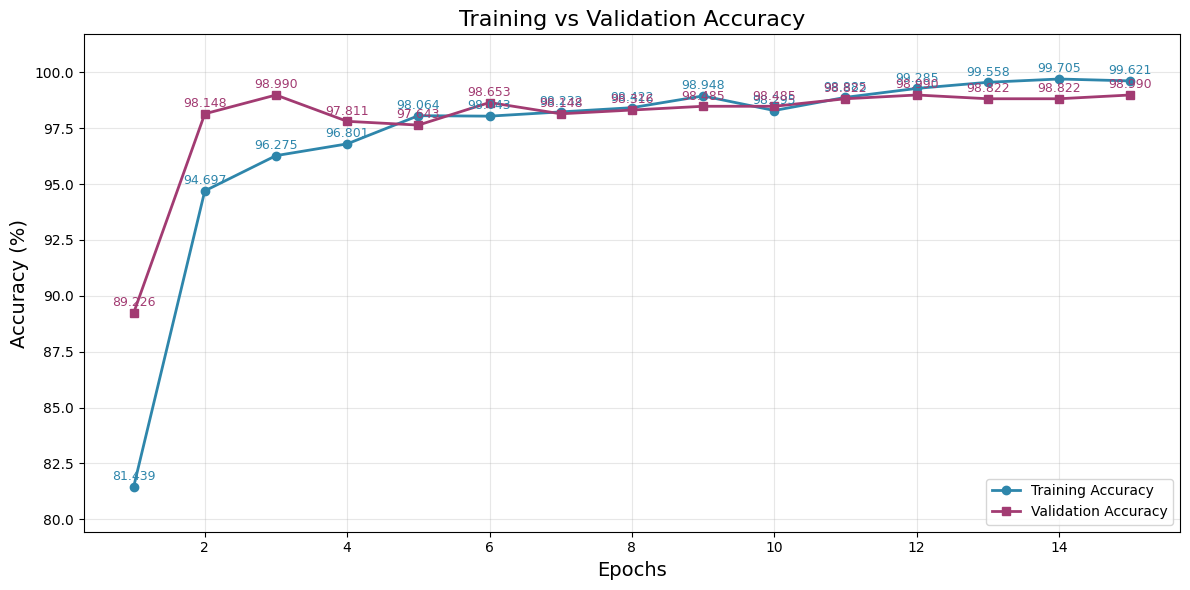

In [112]:
import matplotlib.pyplot as plt
import numpy as np

# Epochs
epochs = range(1, len(train_acc_history) + 1)

# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# Plot lines
ax.plot(
    epochs,
    train_acc_history,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Training Accuracy"
)

ax.plot(
    epochs,
    val_acc_history,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Validation Accuracy"
)

# Add annotations
for i in range(len(train_acc_history)):
    
    # Train annotation
    ax.text(
        epochs[i],
        train_acc_history[i] + 0.3,
        f"{train_acc_history[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation annotation
    ax.text(
        epochs[i],
        val_acc_history[i] + 0.3,
        f"{val_acc_history[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# Labels and title
ax.set_title("Training vs Validation Accuracy", fontsize=16)
ax.set_xlabel("Epochs", fontsize=14)
ax.set_ylabel("Accuracy (%)", fontsize=14)

# Dynamic y-axis
all_values = train_acc_history + val_acc_history
ax.set_ylim(min(all_values)-2, max(all_values)+2)

# Grid and legend
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

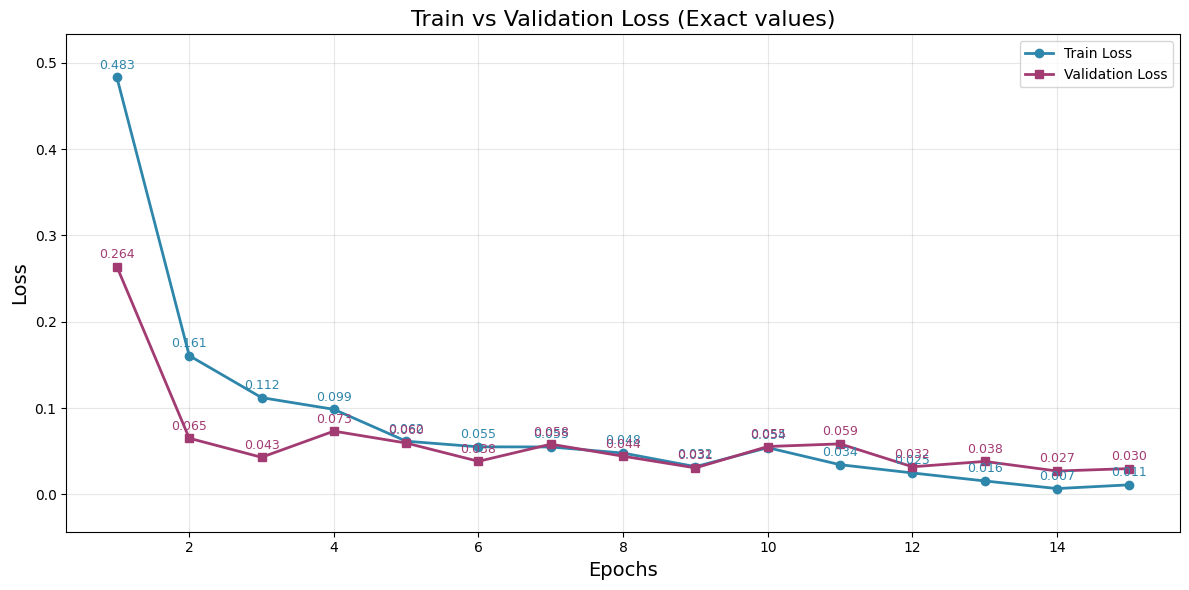

In [113]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics
train_loss = train_loss_history
val_loss = val_loss_history

epochs = range(1, len(train_loss) + 1)

# Create figure
fig, ax = plt.subplots(figsize=(12, 6))

# =========================
# Loss Plot
# =========================
ax.plot(
    epochs,
    train_loss,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Train Loss"
)

ax.plot(
    epochs,
    val_loss,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Validation Loss"
)

# =========================
# Annotate Values
# =========================
for i in range(len(train_loss)):

    # Train loss values
    ax.text(
        epochs[i],
        train_loss[i] + 0.01,
        f"{train_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation loss values
    ax.text(
        epochs[i],
        val_loss[i] + 0.01,
        f"{val_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# =========================
# Labels and Title
# =========================
ax.set_title("Train vs Validation Loss (Exact values)", fontsize=16)
ax.set_xlabel("Epochs", fontsize=14)
ax.set_ylabel("Loss", fontsize=14)

# Dynamic Y-axis
all_values = train_loss + val_loss
ax.set_ylim(min(all_values) - 0.05, max(all_values) + 0.05)

# Grid and legend
ax.grid(alpha=0.3)
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

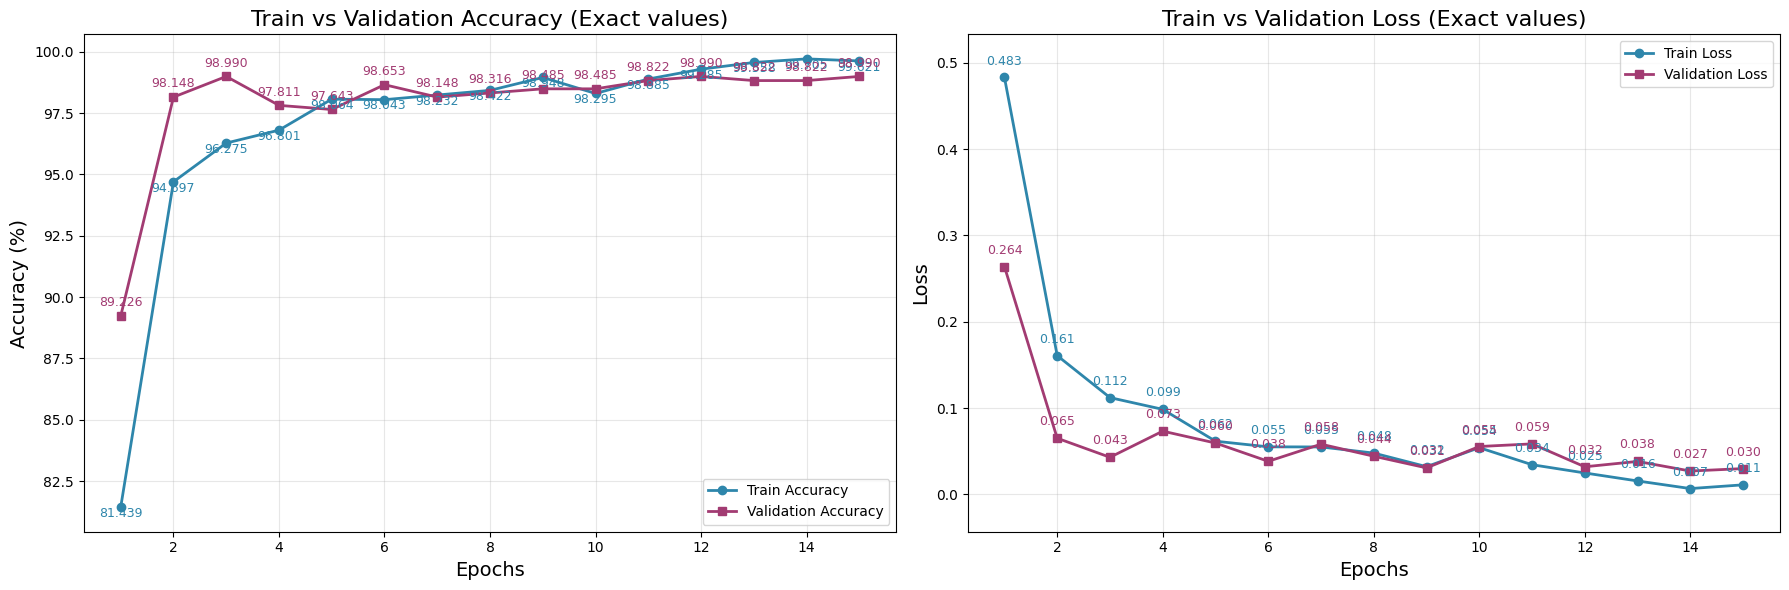

In [114]:
import matplotlib.pyplot as plt
import numpy as np

# =========================
# Metrics
# =========================
train_acc = train_acc_history
val_acc = val_acc_history

train_loss = train_loss_history
val_loss = val_loss_history

epochs = range(1, len(train_acc) + 1)

# =========================
# Create Figure
# =========================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# =========================================================
# LEFT SIDE → ACCURACY
# =========================================================
ax1.plot(
    epochs,
    train_acc,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Train Accuracy"
)

ax1.plot(
    epochs,
    val_acc,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Validation Accuracy"
)

# Accuracy annotations
for i in range(len(train_acc)):

    # Train accuracy text
    ax1.text(
        epochs[i],
        train_acc[i] - 0.4,
        f"{train_acc[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation accuracy text
    ax1.text(
        epochs[i],
        val_acc[i] + 0.4,
        f"{val_acc[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# Accuracy labels
ax1.set_title("Train vs Validation Accuracy (Exact values)", fontsize=16)
ax1.set_xlabel("Epochs", fontsize=14)
ax1.set_ylabel("Accuracy (%)", fontsize=14)

# Dynamic accuracy limits
acc_values = train_acc + val_acc
ax1.set_ylim(min(acc_values) - 1, max(acc_values) + 1)

ax1.grid(alpha=0.3)
ax1.legend()

# =========================================================
# RIGHT SIDE → LOSS
# =========================================================
ax2.plot(
    epochs,
    train_loss,
    color="#2E86AB",
    linewidth=2,
    marker='o',
    label="Train Loss"
)

ax2.plot(
    epochs,
    val_loss,
    color="#A23B72",
    linewidth=2,
    marker='s',
    label="Validation Loss"
)

# Loss annotations
for i in range(len(train_loss)):

    # Train loss text
    ax2.text(
        epochs[i],
        train_loss[i] + 0.015,
        f"{train_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#2E86AB"
    )

    # Validation loss text
    ax2.text(
        epochs[i],
        val_loss[i] + 0.015,
        f"{val_loss[i]:.3f}",
        ha='center',
        fontsize=9,
        color="#A23B72"
    )

# Loss labels
ax2.set_title("Train vs Validation Loss (Exact values)", fontsize=16)
ax2.set_xlabel("Epochs", fontsize=14)
ax2.set_ylabel("Loss", fontsize=14)

# Dynamic loss limits
loss_values = train_loss + val_loss
ax2.set_ylim(min(loss_values) - 0.05, max(loss_values) + 0.05)

ax2.grid(alpha=0.3)
ax2.legend()

# =========================
# Final Layout
# =========================
plt.tight_layout()
plt.show()

In [115]:
accuracy = accuracy_score(all_labels, all_preds)

precision = precision_score(
    all_labels,
    all_preds,
    average='weighted'
)

recall = recall_score(
    all_labels,
    all_preds,
    average='weighted'
)

f1 = f1_score(
    all_labels,
    all_preds,
    average='weighted'
)

print("\n========== OVERALL METRICS ==========\n")

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1 Score : {f1*100:.2f}%")


========== OVERALL METRICS ==========

Accuracy : 98.99%
Precision: 98.99%
Recall   : 98.99%
F1 Score : 98.99%


In [116]:
print("\n========== CLASSIFICATION REPORT ==========\n")

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names
)

print(report)


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

      glioma       0.99      0.99      0.99       219
  meningioma       0.98      0.99      0.98       148
    no_tumor       0.99      1.00      0.99        79
   pituitary       1.00      0.99      1.00       148

    accuracy                           0.99       594
   macro avg       0.99      0.99      0.99       594
weighted avg       0.99      0.99      0.99       594



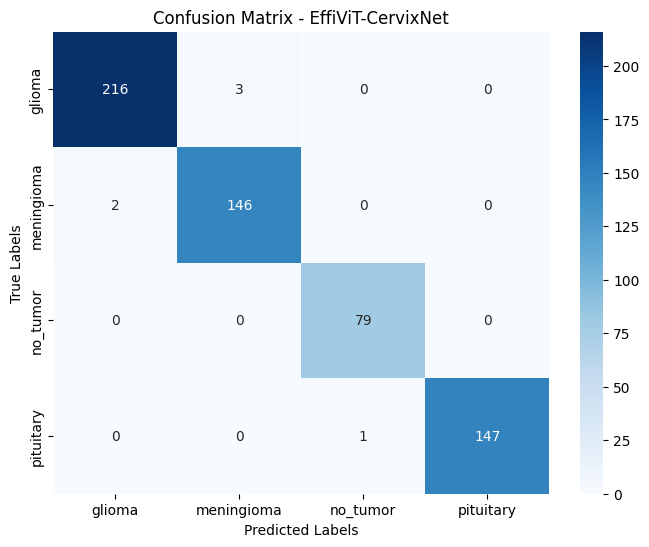

In [117]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")

plt.title("Confusion Matrix - EffiViT-CervixNet")

plt.show()

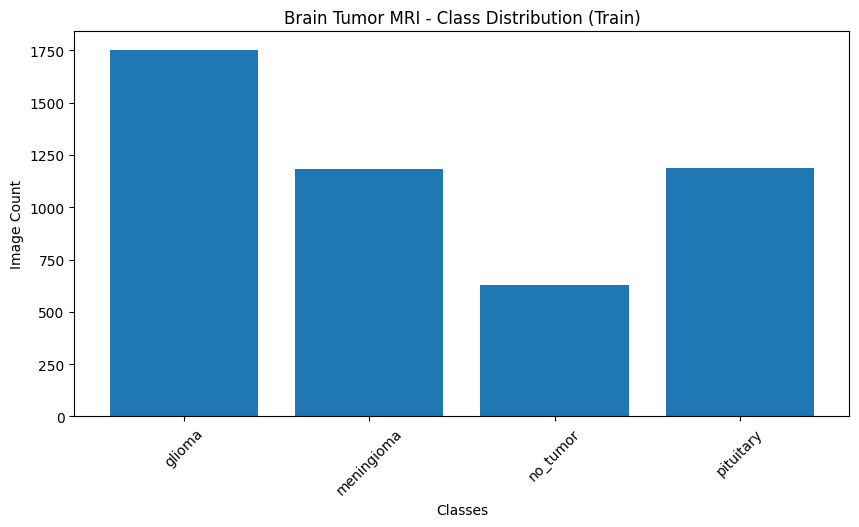

In [118]:
from collections import Counter

labels_list = [label for _, label in train_dataset.samples]

label_counts = Counter(labels_list)

class_counts = [label_counts[i] for i in range(len(class_names))]

plt.figure(figsize=(10,5))

plt.bar(class_names, class_counts)

plt.xticks(rotation=45)

plt.xlabel("Classes")
plt.ylabel("Image Count")

plt.title("Brain Tumor MRI - Class Distribution (Train)")

plt.show()


In [119]:
!pip install lime -q
!pip install grad-cam -q

In [120]:
import cv2
import lime
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from skimage.segmentation import mark_boundaries

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# ROC-AUC Score and Visualization

Micro-average ROC-AUC Score: 0.9996
  glioma ROC-AUC: 0.9995
  meningioma ROC-AUC: 0.9994
  no_tumor ROC-AUC: 0.9999
  pituitary ROC-AUC: 0.9997


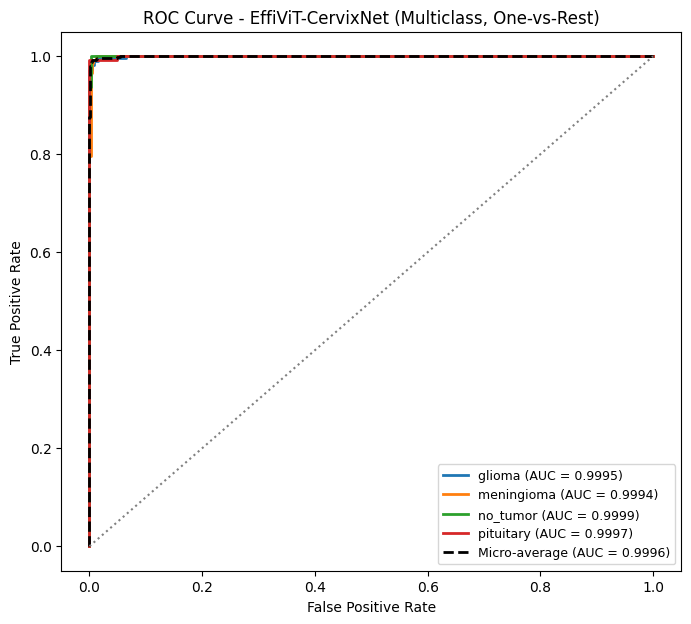

In [121]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import torch
import numpy as np

# ==========================
# SET MODEL TO EVAL MODE
# ==========================
model.eval()

# ==========================
# STORE LABELS & PROBABILITIES
# ==========================
y_true = []
y_prob = []

# ==========================
# CHANGE THIS LOADER NAME
# ==========================
loader = val_loader

# ==========================
# EVALUATION
# ==========================
with torch.no_grad():
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)

        y_prob.extend(probs.cpu().numpy())
        y_true.extend(labels.cpu().numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

num_classes = len(class_names)

# ==========================
# ONE-HOT ENCODE TRUE LABELS (needed for multiclass ROC)
# ==========================
y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))

# ==========================
# ROC CURVE + AUC PER CLASS
# ==========================
fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ==========================
# MICRO-AVERAGE ROC (overall)
# ==========================
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_prob.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

print(f"Micro-average ROC-AUC Score: {roc_auc['micro']:.4f}")
for i in range(num_classes):
    print(f"  {class_names[i]} ROC-AUC: {roc_auc[i]:.4f}")

# ==========================
# VISUALIZATION
# ==========================
plt.figure(figsize=(8, 7))

for i in range(num_classes):
    plt.plot(
        fpr[i], tpr[i], linewidth=2,
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.4f})'
    )

plt.plot(
    fpr["micro"], tpr["micro"],
    linestyle='--', linewidth=2, color='black',
    label=f'Micro-average (AUC = {roc_auc["micro"]:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle=':', color='gray')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - EffiViT-CervixNet (Multiclass, One-vs-Rest)")
plt.legend(loc="lower right", fontsize=9)
plt.show()

In [122]:
import time

# ==========================
# START TIMER
# ==========================
start_time = time.time()

# ==========================
# TRAINING LOOP
# ==========================
for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {running_loss:.4f}")

# ==========================
# END TIMER
# ==========================
end_time = time.time()

training_time = end_time - start_time

print(f"\nTraining Time: {training_time:.2f} seconds")
print(f"Training Time: {training_time/60:.2f} minutes")

Epoch [1/15], Loss: 9.8072
Epoch [2/15], Loss: 7.0181
Epoch [3/15], Loss: 5.1548
Epoch [4/15], Loss: 4.9342
Epoch [5/15], Loss: 2.9248
Epoch [6/15], Loss: 4.9671
Epoch [7/15], Loss: 4.5523
Epoch [8/15], Loss: 2.4560
Epoch [9/15], Loss: 3.3658
Epoch [10/15], Loss: 2.8162
Epoch [11/15], Loss: 1.2695
Epoch [12/15], Loss: 1.9948
Epoch [13/15], Loss: 4.0225
Epoch [14/15], Loss: 3.0962
Epoch [15/15], Loss: 1.5568

Training Time: 1170.17 seconds
Training Time: 19.50 minutes


# Parameter Count

In [123]:
# ==========================
# TOTAL PARAMETERS
# ==========================
total_params = sum(p.numel() for p in model.parameters())

# ==========================
# TRAINABLE PARAMETERS
# ==========================
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 19,092,036
Trainable Parameters: 19,092,036


# FLOPs / GMACs / Computational Complexity

In [124]:
!pip install ptflops

In [125]:
from ptflops import get_model_complexity_info

# ==========================
# COMPUTATIONAL COMPLEXITY
# ==========================
macs, params = get_model_complexity_info(
    model,
    (3, 224, 224),
    as_strings=True,
    print_per_layer_stat=False,
    verbose=False
)

print(f"Computational Complexity (MACs): {macs}")
print(f"Parameters: {params}")

Computational Complexity (MACs): 4.35 GMac
Parameters: 19.09 M


# Convert MACs to GMACs

In [126]:
from ptflops import get_model_complexity_info

macs, params = get_model_complexity_info(
    model,
    (3, 224, 224),
    as_strings=False,
    print_per_layer_stat=False,
    verbose=False
)

gmacs = macs / 1e9

print(f"GMACs: {gmacs:.4f}")

GMACs: 4.3511


# Warmup Cell

In [127]:
import torch
import time
import numpy as np

# ==========================
# EVALUATION MODE
# ==========================
model.eval()

# ==========================
# SELECT YOUR LOADER
# ==========================
loader = val_loader

# Example:
# loader = test_dl
# loader = valid_loader

# ==========================
# GPU WARMUP
# ==========================
with torch.no_grad():

    for images, labels in loader:

        images = images.to(device)

        _ = model(images)

        break

print("Warmup Complete")

Warmup Complete


# Inference Time + Latency

In [128]:
# ==========================
# INITIALIZE VARIABLES
# ==========================
total_time = 0
total_images = 0

# ==========================
# INFERENCE MEASUREMENT
# ==========================
model.eval()

with torch.no_grad():

    for images, labels in loader:

        images = images.to(device)

        batch_size = images.size(0)

        # Start Timer
        start_time = time.time()

        outputs = model(images)

        # GPU Synchronization
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        # End Timer
        end_time = time.time()

        # Batch Inference Time
        inference_time = end_time - start_time

        total_time += inference_time
        total_images += batch_size

# ==========================
# FINAL RESULTS
# ==========================
avg_latency = total_time / total_images

fps = total_images / total_time

print(f"Total Inference Time: {total_time:.4f} seconds")

print(f"Average Latency per Image: {avg_latency*1000:.4f} ms")

print(f"Throughput (FPS): {fps:.2f} images/second")

Total Inference Time: 2.8369 seconds
Average Latency per Image: 4.7760 ms
Throughput (FPS): 209.38 images/second


In [129]:
model.load_state_dict(
    torch.load("best_denseVit_cervixnet.pth")
)

model.eval()

MobileViTCervixNet(
  (cnn): DenseNet(
    (features): Sequential(
      (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu0): ReLU(inplace=True)
      (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (denseblock1): _DenseBlock(
        (denselayer1): _DenseLayer(
          (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu1): ReLU(inplace=True)
          (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu2): ReLU(inplace=True)
          (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (denselayer2): _DenseLayer(
          (norm1): BatchNorm2d(96, eps=1e-05, momen

In [130]:
eval_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [131]:
image_index = 0  

img_path = test_dataset.samples[image_index][0]

original_image = Image.open(img_path).convert("RGB")

true_label = test_dataset.samples[image_index][1]

input_image = eval_transform(original_image)

input_tensor = input_image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(input_tensor)
    pred_label = torch.argmax(output, dim=1).item()

print("True Class:", class_names[true_label])
print("Predicted Class:", class_names[pred_label])


True Class: glioma
Predicted Class: glioma


In [132]:
# ===== ALTERNATIVE - random image select =====
import random

image_index = random.randint(0, len(test_dataset) - 1)

img_path = test_dataset.samples[image_index][0]

original_image = Image.open(img_path).convert("RGB")

true_label = test_dataset.samples[image_index][1]

input_image = eval_transform(original_image)

input_tensor = input_image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(input_tensor)
    pred_label = torch.argmax(output, dim=1).item()

print("Selected index:", image_index)
print("True Class:", class_names[true_label])
print("Predicted Class:", class_names[pred_label])


Selected index: 306
True Class: meningioma
Predicted Class: meningioma


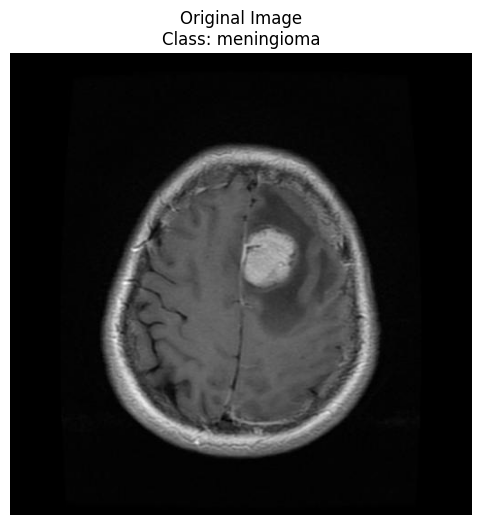

In [133]:
plt.figure(figsize=(6,6))

plt.imshow(original_image)

plt.title(f"Original Image\nClass: {class_names[true_label]}")

plt.axis('off')

plt.show()

In [134]:
target_layers = [model.cnn.features[-1]]

In [135]:
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

cam = GradCAMPlusPlus(
    model=model,
    target_layers=target_layers
)

targets = [ClassifierOutputTarget(pred_label)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0, :]

In [136]:
rgb_image = np.array(
    original_image.resize((224,224))
) / 255.0

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

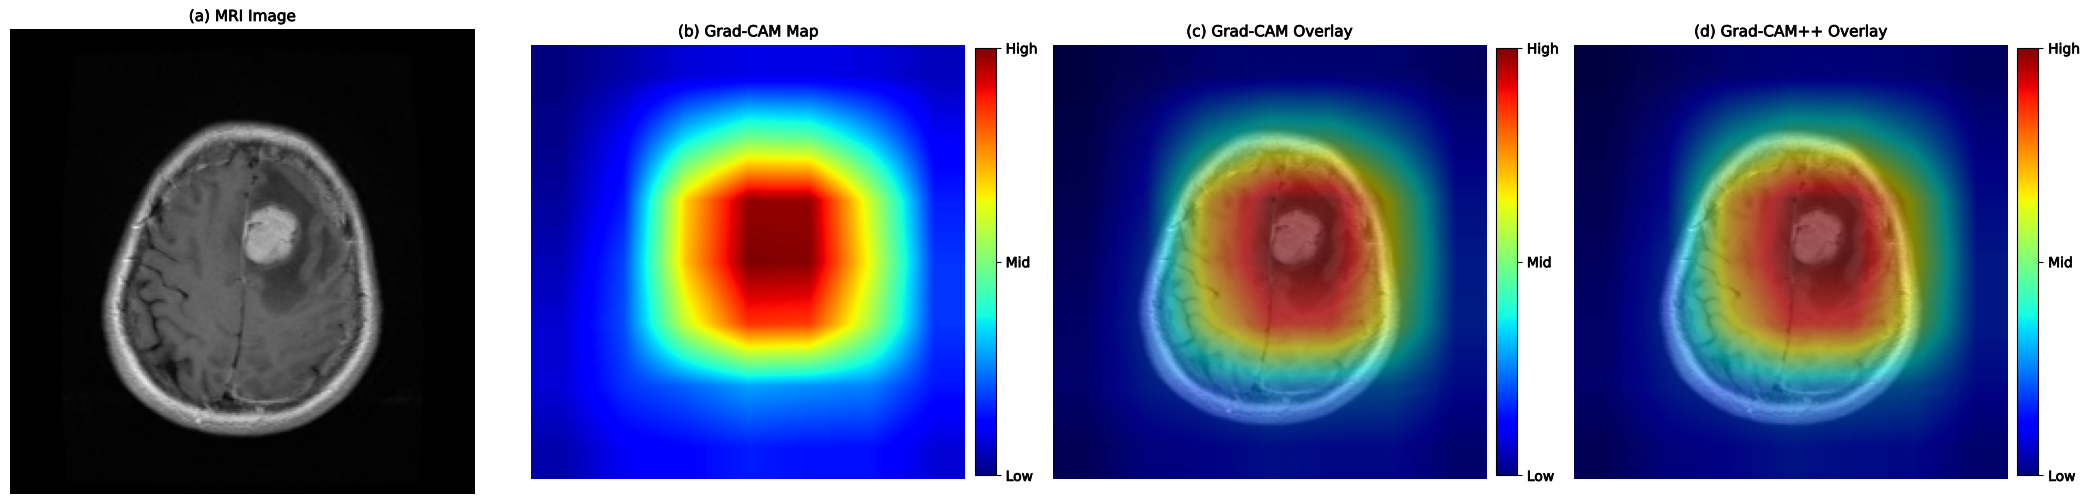

In [137]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image

targets = None

with GradCAM(model=model, target_layers=target_layers) as cam:
    gradcam_map = cam(input_tensor=input_tensor, targets=targets)[0]

with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam_pp:
    gradcampp_map = cam_pp(input_tensor=input_tensor, targets=targets)[0]

rgb = np.clip(rgb_image, 0, 1).astype(np.float32)

gradcam_overlay = show_cam_on_image(rgb, gradcam_map, use_rgb=True, image_weight=0.5)
gradcampp_overlay = show_cam_on_image(rgb, gradcampp_map, use_rgb=True, image_weight=0.5)

dark = [pe.withStroke(linewidth=0.5, foreground='black')]
title_style = dict(fontsize=11, fontweight='medium', color='black', path_effects=dark)

fig, axes = plt.subplots(1, 4, figsize=(21, 5.5))

images = [
    (rgb, "(a) MRI Image"),
    (gradcam_map, "(b) Grad-CAM Map"),
    (gradcam_overlay, "(c) Grad-CAM Overlay"),
    (gradcampp_overlay, "(d) Grad-CAM++ Overlay"),
]

for i, (ax, (img, title)) in enumerate(zip(axes, images)):
    if i == 1:
        ax.imshow(img, cmap='jet', vmin=0, vmax=1)
    else:
        ax.imshow(img)
    ax.set_title(title, **title_style)
    ax.axis('off')

sm = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap='jet')
sm.set_array([])

for ax in axes[1:]:
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.set_ticks([0, 0.5, 1])
    cbar.set_ticklabels(["Low", "Mid", "High"])
    cbar.ax.tick_params(labelsize=10, colors='black')
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_color('black')
        lbl.set_path_effects(dark)

plt.tight_layout()
plt.savefig("gradcam_visualization.png", dpi=300, bbox_inches='tight')
plt.show()

In [138]:
input_tensor_saliency = input_image.unsqueeze(0).to(device)

input_tensor_saliency.requires_grad_()

output = model(input_tensor_saliency)

score = output[0, pred_label]

score.backward()

In [139]:
saliency = input_tensor_saliency.grad.data.abs()

saliency, _ = torch.max(
    saliency,
    dim=1
)

saliency = saliency.squeeze().cpu().numpy()

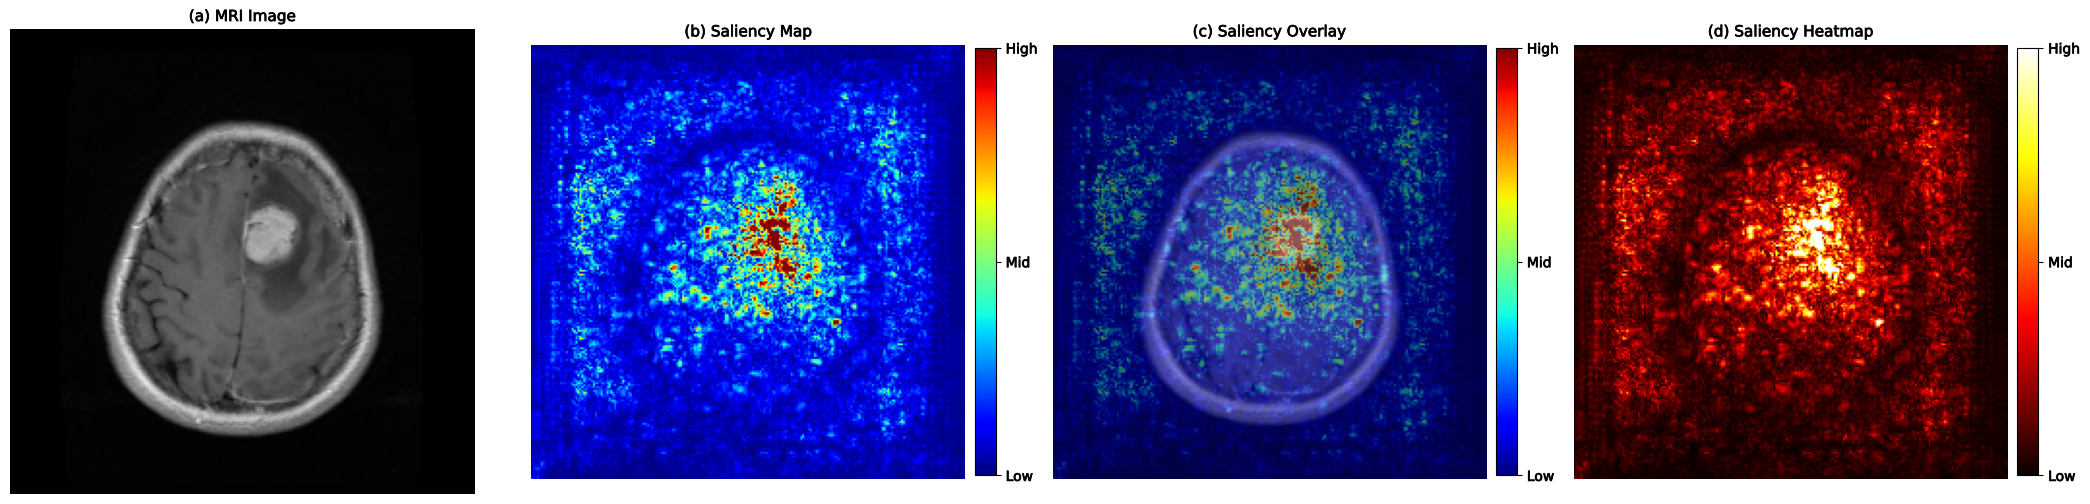

In [140]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import cm
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

rgb = np.clip(rgb_image, 0, 1).astype(np.float32)

sal = np.asarray(saliency, dtype=np.float32)
sal = sal - sal.min()
sal = sal / (np.percentile(sal, 99.5) + 1e-8)
sal = np.clip(sal, 0, 1)

overlay = 0.5 * rgb + 0.5 * cm.jet(sal)[..., :3]
overlay = np.clip(overlay, 0, 1)

dark = [pe.withStroke(linewidth=0.5, foreground='black')]
title_style = dict(fontsize=11, fontweight='medium', color='black', path_effects=dark)

fig, axes = plt.subplots(1, 4, figsize=(21, 5.5))

axes[0].imshow(rgb)
axes[0].set_title("(a) MRI Image", **title_style)

axes[1].imshow(sal, cmap='jet', vmin=0, vmax=1)
axes[1].set_title("(b) Saliency Map", **title_style)

axes[2].imshow(overlay)
axes[2].set_title("(c) Saliency Overlay", **title_style)

axes[3].imshow(sal, cmap='hot', vmin=0, vmax=1)
axes[3].set_title("(d) Saliency Heatmap", **title_style)

for ax in axes:
    ax.axis('off')

for ax, cmap_name in zip(axes[1:], ['jet', 'jet', 'hot']):
    sm = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap=cmap_name)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.set_ticks([0, 0.5, 1])
    cbar.set_ticklabels(["Low", "Mid", "High"])
    cbar.ax.tick_params(labelsize=10, colors='black')
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_color('black')
        lbl.set_path_effects(dark)

plt.tight_layout()
plt.savefig("saliency_visualization.png", dpi=300, bbox_inches='tight')
plt.show()

In [141]:
from lime import lime_image

In [142]:
explainer = lime_image.LimeImageExplainer()

In [143]:
def batch_predict(images):

    model.eval()

    batch = torch.stack([

        eval_transform(
            Image.fromarray(img)
        )

        for img in images

    ], dim=0).to(device)

    with torch.no_grad():

        logits = model(batch)

        probs = torch.softmax(
            logits,
            dim=1
        )
        
    return probs.cpu().numpy()

In [144]:
lime_image_input = np.array(
    original_image.resize((224,224))
)

In [145]:
explanation = explainer.explain_instance(

    lime_image_input,

    batch_predict,

    top_labels=1,

    hide_color=0,

    num_samples=1000
)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [146]:
temp, mask = explanation.get_image_and_mask(

    explanation.top_labels[0],

    positive_only=True,

    num_features=5,

    hide_rest=False
)

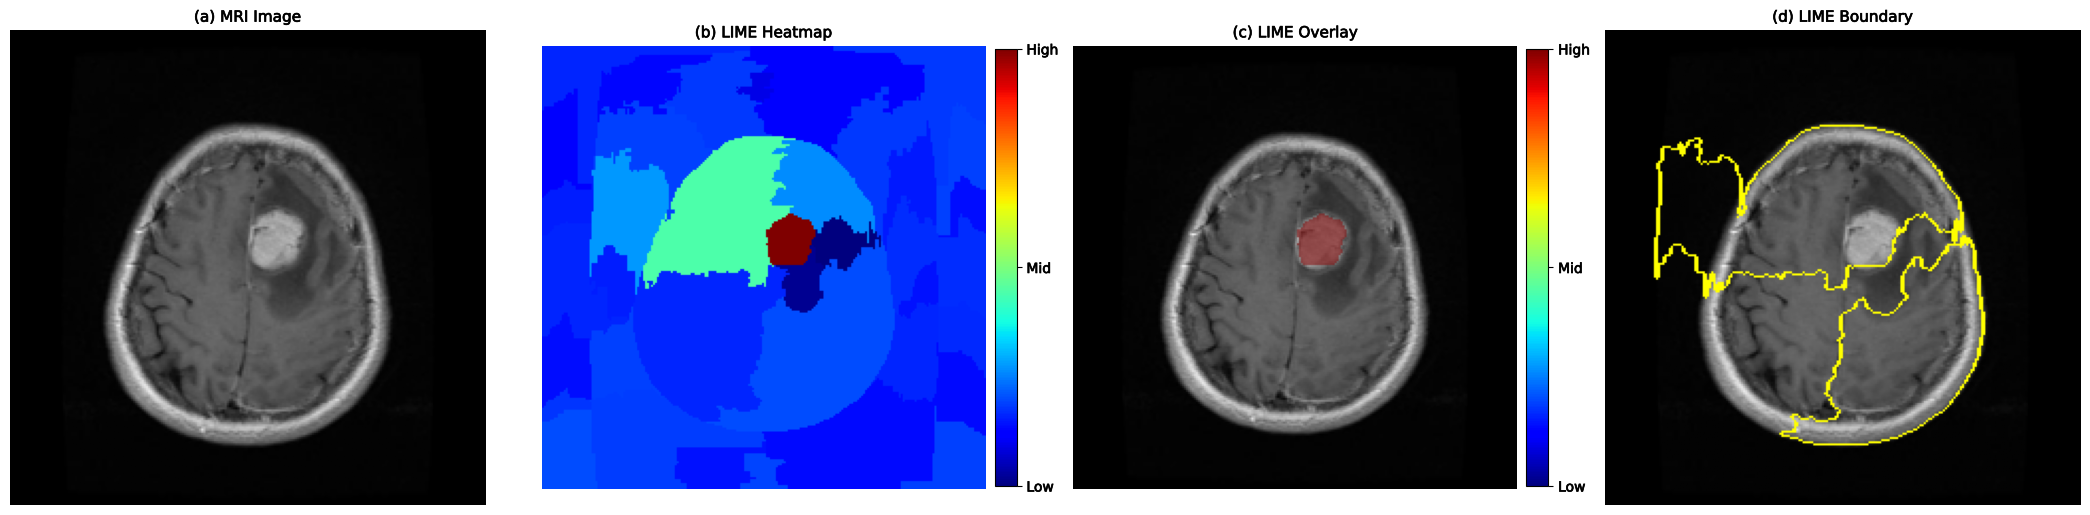

In [147]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import cm
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from skimage.segmentation import mark_boundaries

label = explanation.top_labels[0]
weights = dict(explanation.local_exp[label])
lime_map = np.vectorize(lambda s: weights.get(s, 0.0))(explanation.segments).astype(np.float32)
lime_map = (lime_map - lime_map.min()) / (lime_map.max() - lime_map.min() + 1e-8)

orig = np.asarray(lime_image_input, dtype=np.float32)
if orig.max() > 1:
    orig = orig / 255.0
orig = np.clip(orig, 0, 1)

heat_rgba = cm.jet(lime_map)
alpha = np.where(lime_map > 0.5, 0.55, 0.0)[..., None]
overlay = np.clip(orig * (1 - alpha) + heat_rgba[..., :3] * alpha, 0, 1)

boundary = mark_boundaries(temp / 255.0, mask)

dark = [pe.withStroke(linewidth=0.5, foreground='black')]
title_style = dict(fontsize=11, fontweight='medium', color='black', path_effects=dark)

fig, axes = plt.subplots(1, 4, figsize=(21, 5.5))

axes[0].imshow(orig)
axes[0].set_title("(a) MRI Image", **title_style)

axes[1].imshow(lime_map, cmap='jet', vmin=0, vmax=1)
axes[1].set_title("(b) LIME Heatmap", **title_style)

axes[2].imshow(overlay)
axes[2].set_title("(c) LIME Overlay", **title_style)

axes[3].imshow(boundary)
axes[3].set_title("(d) LIME Boundary", **title_style)

for ax in axes:
    ax.axis('off')

sm = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap='jet')
sm.set_array([])

for ax in axes[1:3]:
    cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.set_ticks([0, 0.5, 1])
    cbar.set_ticklabels(["Low", "Mid", "High"])
    cbar.ax.tick_params(labelsize=10, colors='black')
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_color('black')
        lbl.set_path_effects(dark)

plt.tight_layout()
plt.savefig("lime_visualization.png", dpi=300, bbox_inches='tight')
plt.show()

True Class      : meningioma
Predicted Class : meningioma  (mean prob: 0.9964)
Predictive Entropy (uncertainty): 0.0241

  glioma                    -> mean: 0.0035  |  std: 0.0023
  meningioma                -> mean: 0.9964  |  std: 0.0023
  no_tumor                  -> mean: 0.0000  |  std: 0.0000
  pituitary                 -> mean: 0.0001  |  std: 0.0000


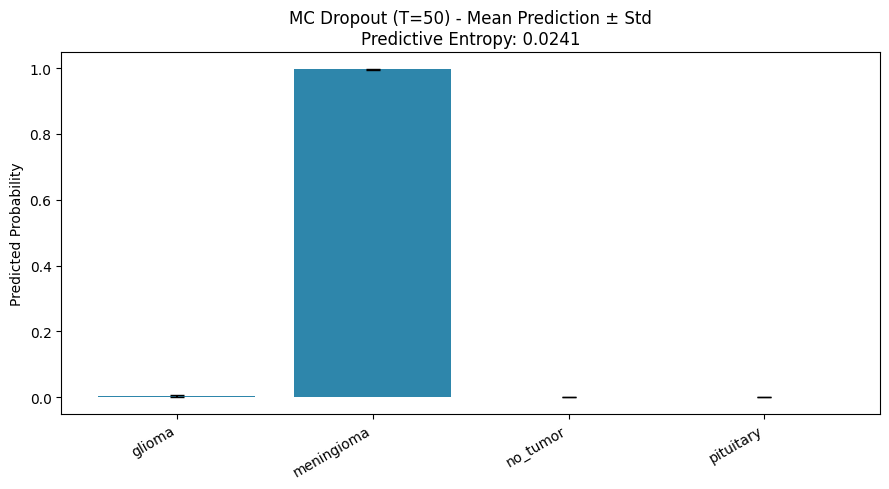

MobileViTCervixNet(
  (cnn): DenseNet(
    (features): Sequential(
      (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu0): ReLU(inplace=True)
      (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (denseblock1): _DenseBlock(
        (denselayer1): _DenseLayer(
          (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu1): ReLU(inplace=True)
          (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu2): ReLU(inplace=True)
          (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        )
        (denselayer2): _DenseLayer(
          (norm1): BatchNorm2d(96, eps=1e-05, momen

In [148]:
# MONTE CARLO DROPOUT (Uncertainty Estimation)

import torch
import numpy as np
import matplotlib.pyplot as plt

def enable_mc_dropout(model):
    """Model overall eval mode-e thakbe (BatchNorm etc thik thakbe),
    kintu shudhu Dropout layer gulo train mode-e (active) rakha hobe."""
    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.train()

T = 50  

model.eval()         
enable_mc_dropout(model)   

mc_probs = []

with torch.no_grad():
    for _ in range(T):
        outputs = model(input_tensor)         
        probs = torch.softmax(outputs, dim=1)
        mc_probs.append(probs.cpu().numpy())

mc_probs = np.array(mc_probs)          
mc_probs = mc_probs.squeeze(1)       
mean_probs = mc_probs.mean(axis=0)
std_probs = mc_probs.std(axis=0)

predicted_class = np.argmax(mean_probs)
predictive_entropy = -np.sum(mean_probs * np.log(mean_probs + 1e-12))

print(f"True Class      : {class_names[true_label]}")
print(f"Predicted Class : {class_names[predicted_class]}  (mean prob: {mean_probs[predicted_class]:.4f})")
print(f"Predictive Entropy (uncertainty): {predictive_entropy:.4f}\n")

for i, cname in enumerate(class_names):
    print(f"  {cname:25s} -> mean: {mean_probs[i]:.4f}  |  std: {std_probs[i]:.4f}")

plt.figure(figsize=(9, 5))

plt.bar(
    class_names,
    mean_probs,
    yerr=std_probs,
    capsize=5,
    color="#2E86AB"
)

plt.xticks(rotation=30, ha="right")
plt.ylabel("Predicted Probability")
plt.title(f"MC Dropout (T={T}) - Mean Prediction ± Std\nPredictive Entropy: {predictive_entropy:.4f}")
plt.tight_layout()
plt.show()
model.eval()